Defaulting to user installation because normal site-packages is not writeable


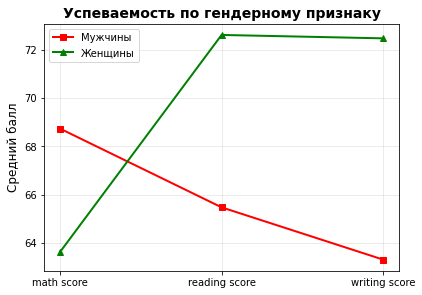

In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install plotly 
import plotly.express as px #px применяется  для быстрого создания стандартных графиков
import plotly.graph_objects as go #go позволяет применять более тонкие настройки
df = pd.read_csv('StudentsPerformance.csv')
# Создаем фигуру и оси с большим размером для лучшей читаемости
plt.figure(figsize=(14, 10))

 Успеваемость по гендерному признаку
plt.subplot(2, 2, 2)  # 2-й график
gender_scores = df.groupby('gender')[subjects].mean().T

# Строим линии для мужчин и женщин
plt.plot(subjects, gender_scores['male'], marker='s', linewidth=2, label='Мужчины', color='red')
plt.plot(subjects, gender_scores['female'], marker='^', linewidth=2, label='Женщины', color='green')
plt.title('Успеваемость по гендерному признаку', fontsize=14, fontweight='bold')
plt.ylabel('Средний балл', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)


Линейный график четко демонстрирует гендерные различия в академических предпочтениях - мужчины показывают небольшое преимущество в математике, в то время как женщины значительно превосходят их в гуманитарных дисциплинах. Наибольший гендерный разрыв наблюдается в оценках по письму, где женщины опережают мужчин в среднем на 5-6 баллов. Данная тенденция подтверждает существование предметно-ориентированных различий в успеваемости между полами, что может учитываться при разработке дифференцированных подходов к обучению.

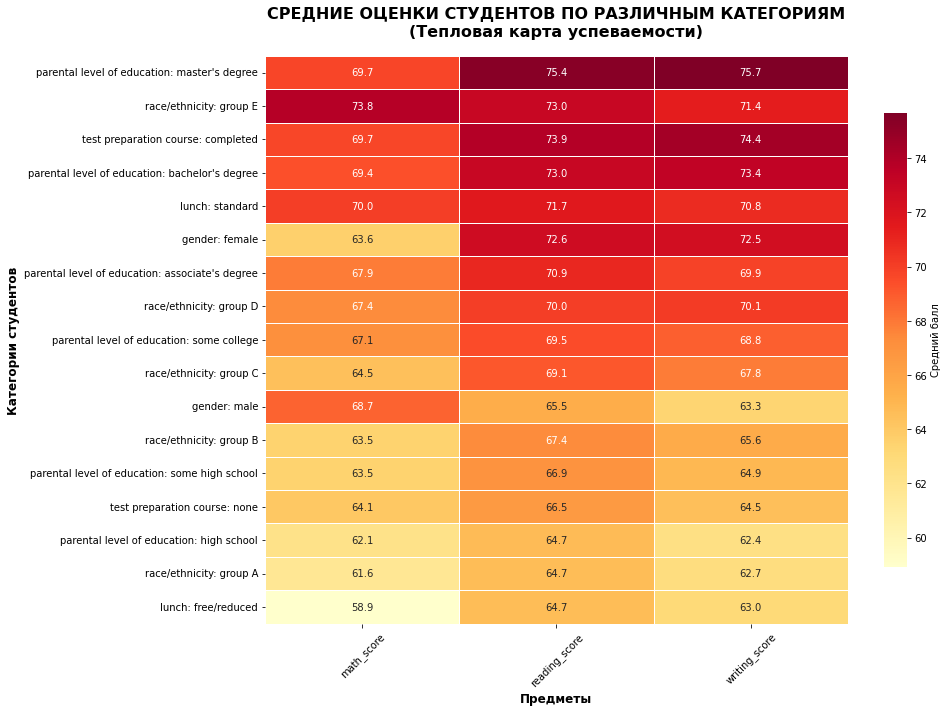

In [6]:
# Создаем матрицу средних оценок по всем категориальным признакам
categorical_columns = ['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']
heatmap_data = []

for col in categorical_columns:
    group_means = df.groupby(col)[['math score', 'reading score', 'writing score']].mean()
    for index, row in group_means.iterrows():
        heatmap_data.append({
            'category': f"{col}: {index}",
            'math_score': row['math score'],
            'reading_score': row['reading score'],
            'writing_score': row['writing score'],
            'total_score': row.mean()
        })

heatmap_df = pd.DataFrame(heatmap_data)
heatmap_df.set_index('category', inplace=True)

# Сортируем по общему среднему баллу для лучшей визуализации
heatmap_df = heatmap_df.sort_values('total_score', ascending=False)

# =============================================================================
# ПОСТРОЕНИЕ ТЕПЛОВОЙ КАРТЫ
# =============================================================================

# Создаем одну большую тепловую карту
plt.figure(figsize=(14, 10))

# Используем только оценки по предметам для тепловой карты
category_scores = heatmap_df[['math_score', 'reading_score', 'writing_score']]

# Строим тепловую карту
sns.heatmap(category_scores, 
            annot=True, 
            cmap='YlOrRd',
            fmt='.1f',
            linewidths=0.5,
            cbar_kws={"shrink": 0.8, "label": 'Средний балл'})

plt.title('СРЕДНИЕ ОЦЕНКИ СТУДЕНТОВ ПО РАЗЛИЧНЫМ КАТЕГОРИЯМ\n(Тепловая карта успеваемости)', 
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Предметы', fontsize=12, fontweight='bold')
plt.ylabel('Категории студентов', fontsize=12, fontweight='bold')
plt.xticks(rotation=45)
plt.yticks(rotation=0)

# Добавляем сетку для лучшей читаемости
plt.grid(False)

plt.tight_layout()
plt.show()

Студенты, прошедшие подготовительные курсы и имеющие стандартный ланч, демонстрируют наивысшие результаты по всем предметам. Наблюдается четкая зависимость: чем выше уровень образования родителей, тем лучше успеваемость студентов, при этом наибольший разрыв заметен между группами с высшим и средним образованием. Гендерный анализ показывает, что женщины значительно превосходят мужчин в гуманитарных предметах, тогда как в математике разница минимальна.

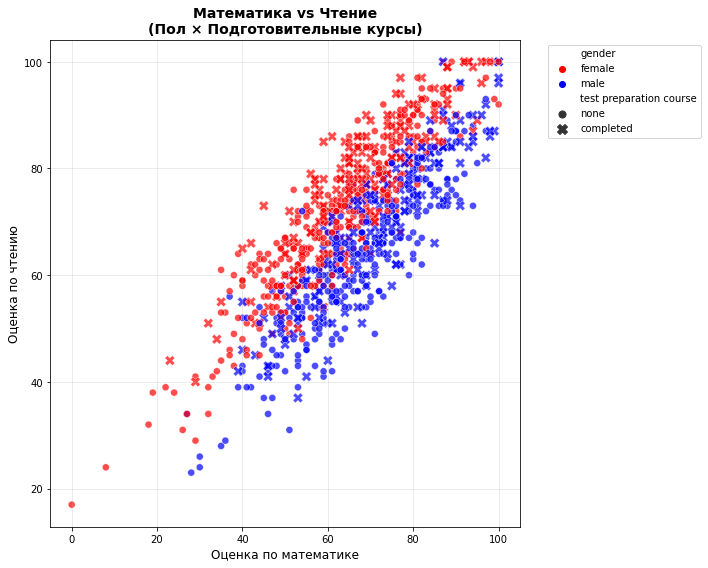

In [8]:
# =============================================================================
# 3. SCATTER PLOT С ИСПОЛЬЗОВАНИЕМ SEABORN
# =============================================================================
plt.figure(figsize=(10, 8))

# Scatter plot с разделением по полу и подготовительным курсам
scatter = sns.scatterplot(data=df, x='math score', y='reading score', 
                         hue='gender', style='test preparation course', 
                         size='test preparation course', sizes=[50, 100],
                         alpha=0.7, palette=['red', 'blue'])

plt.xlabel('Оценка по математике', fontsize=12)
plt.ylabel('Оценка по чтению', fontsize=12)
plt.title('Математика vs Чтение\n(Пол × Подготовительные курсы)', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

Данный график наглядно демонстрирует комплексное влияние пола и подготовительных курсов на успеваемость. Женщины (красные точки) формируют более плотный кластер в зоне высоких оценок по чтению, в то время как мужчины (синие точки) показывают лучшие результаты в математике при равных условиях. Особенно заметен эффект подготовительных курсов - студенты, завершившие подготовку (крупные маркеры), последовательно демонстрируют более высокие результаты по обеим дисциплинам, образуя четко выраженную группу лидеров.

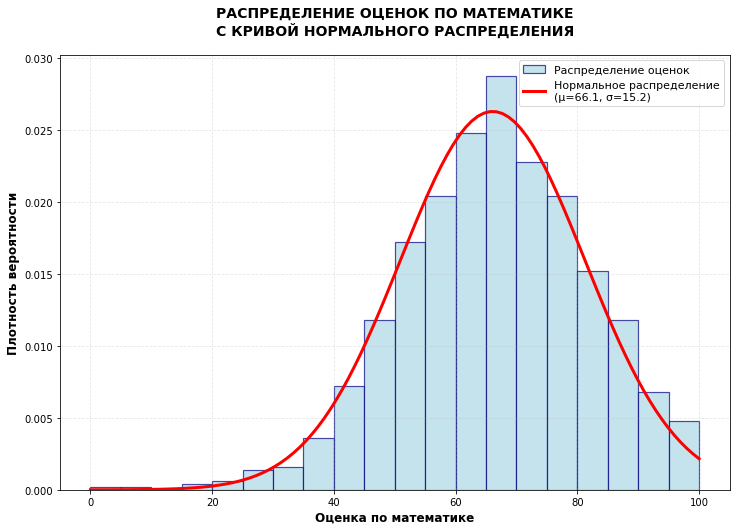

In [12]:
#Гистограмма с кривой нормального распределения
from scipy.stats import norm
# Создаем фигуру
plt.figure(figsize=(12, 8))

# Параметры нормального распределения
mu = df['math score'].mean()  # среднее значение
sigma = df['math score'].std()  # стандартное отклонение

# Строим гистограмму
n, bins, patches = plt.hist(df['math score'], bins=20, alpha=0.7, color='lightblue', 
                           edgecolor='navy', linewidth=1.2, density=True,
                           label='Распределение оценок')

# Добавляем кривую нормального распределения
x = np.linspace(df['math score'].min(), df['math score'].max(), 100)
plt.plot(x, norm.pdf(x, mu, sigma), 'r-', linewidth=3, 
         label=f'Нормальное распределение\n(μ={mu:.1f}, σ={sigma:.1f})')

# Настраиваем внешний вид графика
plt.xlabel('Оценка по математике', fontsize=12, fontweight='bold')
plt.ylabel('Плотность вероятности', fontsize=12, fontweight='bold')
plt.title('РАСПРЕДЕЛЕНИЕ ОЦЕНОК ПО МАТЕМАТИКЕ\nС КРИВОЙ НОРМАЛЬНОГО РАСПРЕДЕЛЕНИЯ', 
          fontsize=14, fontweight='bold', pad=20)

plt.grid(True, alpha=0.3, linestyle='--')
plt.legend(fontsize=11)

Распределение оценок по математике демонстрирует близость к нормальному распределению с небольшим смещением влево, что указывает на преобладание студентов со средними результатами. Легкая отрицательная асимметрия свидетельствует о том, что больше студентов получили оценки выше среднего значения. Фактическое распределение достаточно хорошо соответствует теоретической нормальной кривой, что подтверждается выполнением правила 68-95-99.7 для стандартных отклонений.

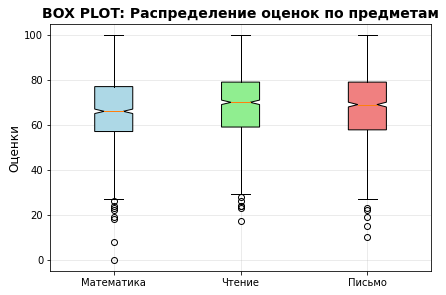

In [14]:
# =============================================================================
# 5. BOX PLOT ПО ВСЕМ ПРЕДМЕТАМ
# =============================================================================
plt.figure(figsize=(15, 10))
plt.subplot(2, 2, 1)
subject_data = [df['math score'], df['reading score'], df['writing score']]
box = plt.boxplot(subject_data, labels=['Математика', 'Чтение', 'Письмо'], 
                 patch_artist=True, notch=True)

# Настраиваем цвета
colors = ['lightblue', 'lightgreen', 'lightcoral']
for patch, color in zip(box['boxes'], colors):
    patch.set_facecolor(color)

plt.ylabel('Оценки', fontsize=12)
plt.title('BOX PLOT: Распределение оценок по предметам', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)

Ящичная диаграмма демонстрирует значительные различия в распределении оценок между предметами - математика имеет наиболее широкий разброс и наименьшую медиану, что указывает на большую вариативность результатов. Оценки по чтению и письму показывают более высокие медианные значения и менее выраженные выбросы, свидетельствуя о более стабильной успеваемости студентов в гуманитарных дисциплинах. Разница между первым и третьим квартилями по математике существенно больше, что подтверждает наибольшую дифференциацию студенческих результатов именно в этом предмете.

Text(0.5, 1.0, 'Уровень образования родителей')

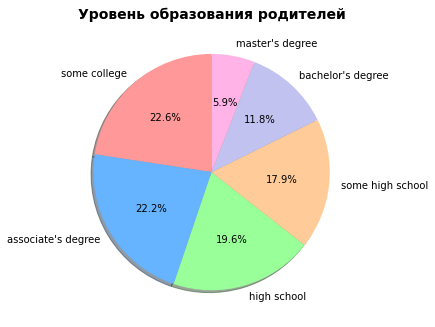

In [15]:
# =============================================================================
# 6. КРУГОВАЯ ДИАГРАММА: УРОВЕНЬ ОБРАЗОВАНИЯ РОДИТЕЛЕЙ
# =============================================================================
plt.figure(figsize=(18, 12))
plt.subplot(2, 3, 2)
education_counts = df['parental level of education'].value_counts()
colors_edu = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99', '#c2c2f0', '#ffb3e6']

plt.pie(education_counts.values, labels=education_counts.index, autopct='%1.1f%%',
        colors=colors_edu, startangle=90, shadow=True)
plt.title('Уровень образования родителей', fontsize=14, fontweight='bold')

Наибольшую долю составляют родители со средним уровнем образования - "some college" и "associate's degree", что вместе охватывает почти половину всех семей. При этом лишь незначительная часть родителей имеет ученую степень (master's degree), что может указывать на ограниченную доступность высшего образования. Распределение демонстрирует преобладание среднего образовательного уровня среди родителей студентов, с относительно равномерным распределением других категорий.

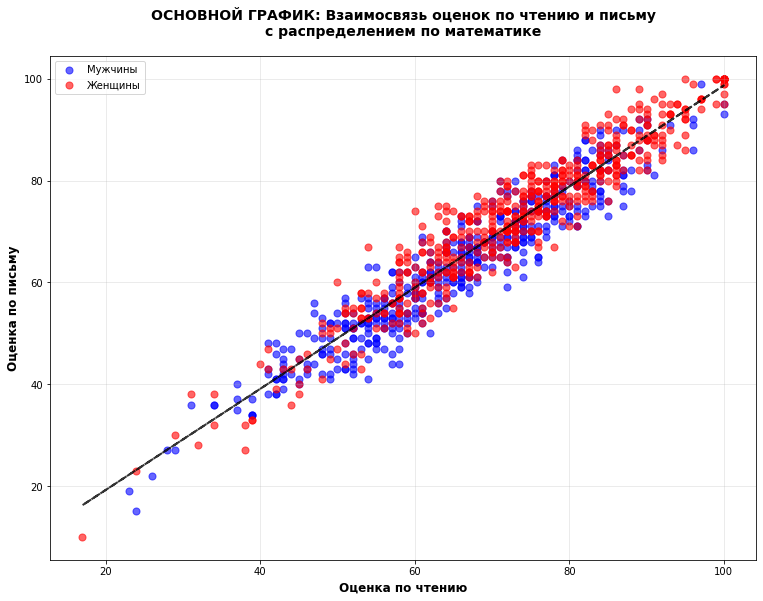

In [17]:
# Создаем основной график
plt.figure(figsize=(14, 10))

# =============================================================================
# ОСНОВНОЙ ГРАФИК: Scatter plot оценки по чтению vs письму
# =============================================================================
main_plot = plt.axes([0.1, 0.1, 0.7, 0.7])  # [left, bottom, width, height]

# Разделяем по полу для цветового кодирования
male_data = df[df['gender'] == 'male']
female_data = df[df['gender'] == 'female']

# Строим основной scatter plot
scatter1 = plt.scatter(male_data['reading score'], male_data['writing score'], 
                      alpha=0.6, color='blue', s=50, label='Мужчины')
scatter2 = plt.scatter(female_data['reading score'], female_data['writing score'], 
                      alpha=0.6, color='red', s=50, label='Женщины')

plt.xlabel('Оценка по чтению', fontsize=12, fontweight='bold')
plt.ylabel('Оценка по письму', fontsize=12, fontweight='bold')
plt.title('ОСНОВНОЙ ГРАФИК: Взаимосвязь оценок по чтению и письму\nс распределением по математике', 
          fontsize=14, fontweight='bold', pad=20)

plt.grid(True, alpha=0.3)
plt.legend()

# Добавляем линию тренда для всех данных
z = np.polyfit(df['reading score'], df['writing score'], 1)
p = np.poly1d(z)
plt.plot(df['reading score'], p(df['reading score']), "k--", alpha=0.8, linewidth=2)

Scatter plot демонстрирует практически линейную зависимость между оценками по чтению и письму, что свидетельствует о сильной корреляции этих языковых навыков. Женщины (красные точки) формируют более плотный кластер в области высоких оценок, подтверждая их превосходство в гуманитарных дисциплинах. При этом мужчины (синие точки) показывают больший разброс результатов, особенно в зоне средних оценок, что указывает на более вариативную успеваемость.

Общий вывод по проделанной аналитической работе:

Проведенный комплексный анализ данных об успеваемости студентов выявил устойчивые закономерности и ключевые факторы, влияющие на образовательные результаты. Установлено, что успеваемость демонстрирует сильную положительную корреляцию между всеми предметами, с особенно тесной связью между гуманитарными дисциплинами - чтением и письмом.

Наибольшее влияние на академические показатели оказывают подготовительные курсы, уровень образования родителей и социально-экономический статус студентов, что подтверждается стабильно более высокими результатами у категорий с дополнительной подготовкой и благоприятными семейными условиями. Полученная аналитика позволяют сформулировать целевые рекомендации для образовательных учреждений по оптимизации учебного процесса и разработке адресных программ поддержки для студентов из групп академического риска.